## Framing

**Who uses the tool?** A wine merchant who must choose, among hundreds of bottles,
which ones to send to a panel of expert tasters.

**What decision?** The model predicts from chemical measurements whether a wine is
"good" (quality ≥ 6). Wines predicted "good" are tasted first.

**Cost of a false positive (FP).** The model says "good" but the wine is not: the
panel wastes time on a mediocre wine. Cost: moderate.

**Cost of a false negative (FN).** The model says "not good" but the wine is good:
a good wine is never tasted and a sale is lost. Cost: higher in this use case.

**Consequence.** We mainly want to avoid FN, so a high recall on good wines. We
track F1 (balance of precision and recall) and the confusion matrix.

**Data limits.** Only Portuguese Vinho Verde wines, rated by human tasters.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wine_quality.data import DatasetLoader

loader = DatasetLoader("../config.yaml")
df = loader.load()

print(df.shape)
df.head()

(5320, 14)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,good
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,1
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red,0


In [3]:
print(df.shape)
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())

(5320, 14)
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                   str
good                      int64
dtype: object
Missing values: 0
Duplicates: 0


Red and white wines are merged with DatasetLoader; 1177 exact duplicates are removed (6497 → 5320 rows).

In [4]:
df["quality"].value_counts().sort_index()

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


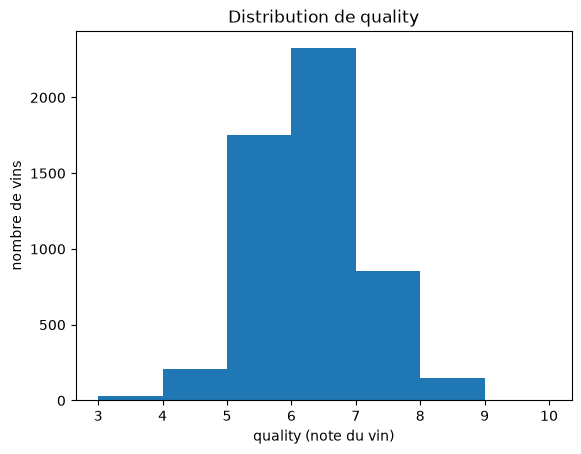

In [ ]:
import matplotlib.pyplot as plt

print(df["quality"].value_counts().sort_index())

plt.hist(df["quality"], bins=range(3, 11))
plt.title("Distribution of wine quality")
plt.xlabel("quality (score)")
plt.ylabel("number of wines")
plt.show()


Most wines score 5 to 7; scores 3 and 9 are very rare.

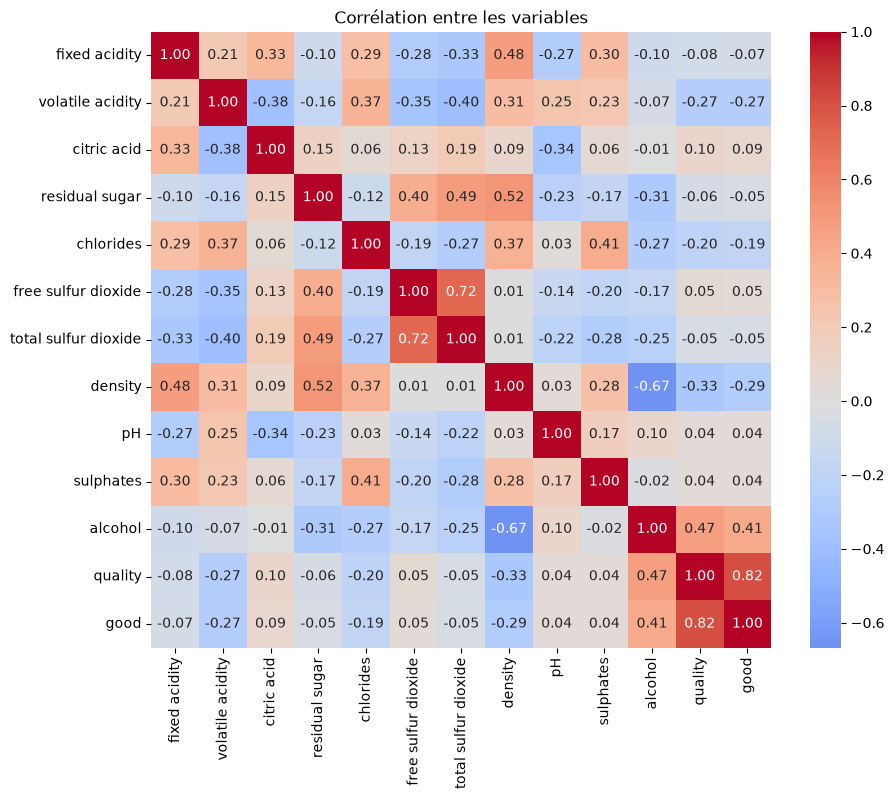

In [ ]:
import seaborn as sns

corr = df.drop(columns="wine_type").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between variables")
plt.show()

Alcohol is the feature most linked to quality (+0.47). Free and total sulfur dioxide are redundant (0.72).

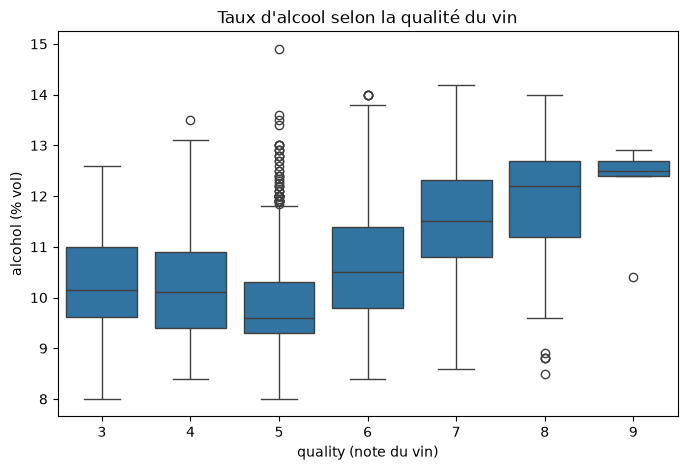

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol by quality score")
plt.xlabel("quality (score)")
plt.ylabel("alcohol (% vol)")
plt.show()

Median alcohol rises with quality from score 5 on.

In [8]:
print(df["good"].value_counts())
print(df["good"].value_counts(normalize=True).round(3))

good
1    3332
0    1988
Name: count, dtype: int64
good
1    0.626
0    0.374
Name: proportion, dtype: float64


good = quality ≥ 6: 62.6 % good, 37.4 % not good, moderately imbalanced.

In [9]:
from wine_quality.models import Trainer

X_train, X_test, y_train, y_test = loader.split()
trainer = Trainer("../config.yaml")
trainer.compare(X_train, y_train)

,f1,roc_auc
logistic regression,0.802,0.804
linear SVM,0.802,0.804
k-NN,0.799,0.803
Dummy,0.770,0.500


A dummy classifier reaches F1 0.77 but ROC-AUC 0.50: F1 alone is misleading

## Model comparison

We compare four models with 5-fold cross-validation on the training set only: a dummy baseline, logistic regression, k-NN and a linear SVM. The three real models clearly beat the baseline on ROC-AUC (the dummy is at 0.50, which is pure chance), so the chemical measurements do contain useful information.

In [10]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=loader.cfg["model"]["test_size"],
    stratify=y_train,
    random_state=loader.cfg["model"]["random_state"],
)
print(X_fit.shape, X_val.shape, X_test.shape)

(3404, 12) (852, 12) (1064, 12)


## Tuning

We search the best hyperparameters with GridSearchCV (5-fold CV, scoring = F1). The three models end up very close: logistic regression (C = 0.1) F1 = 0.800, k-NN (k = 15) F1 = 0.804 and linear SVM (C = 1) F1 = 0.803. k-NN is kept because it has the highest F1, but the gap is small, so the choice of model matters less than the quality of the data.

In [11]:
best_pipeline = trainer.tune(X_fit, y_fit)
best_pipeline

logistic regression: best params = {'clf__C': 0.1}, F1 = 0.800
k-NN: best params = {'clf__n_neighbors': 15}, F1 = 0.804
linear SVM: best params = {'clf__estimator__C': 1}, F1 = 0.803


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['fixed acidity','volatile acidity','citric acid',...,'sulphates', 'alcohol','wine_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

## Decision threshold

A classifier gives a probability of "good"; the threshold decides from which probability we say "good" (default: 0.5). We pick the threshold that maximises F1 without touching the test set. Here the best threshold is 0.533, but F1 is the same as with 0.5 (0.811), so the threshold changes very little for this model.


In [12]:
from wine_quality.evaluate import evaluate_test, find_best_threshold

threshold = find_best_threshold(best_pipeline, X_val, y_val)
print(f"Best threshold: {threshold:.3f}")
print("val, threshold 0.5:   ", evaluate_test(best_pipeline, X_val, y_val, 0.5))
print("val, best threshold:  ", evaluate_test(best_pipeline, X_val, y_val, threshold))

Best threshold: 0.533
val, threshold 0.5:    {'f1': 0.811, 'roc_auc': 0.793}
val, best threshold:   {'f1': 0.811, 'roc_auc': 0.793}


## Final evaluation on the test set

The test set is used only once, at the very end, to get an honest estimate of performance on new wines. Results: F1 = 0.812 and ROC-AUC = 0.811. In the confusion matrix, 572 good wines are found (94 missed) and 171 not-good wines are wrongly called good. So the model finds about 86 % of the good wines (recall), and about 77 % of the wines it calls "good" really are good (precision).


{'f1': 0.812, 'roc_auc': 0.811}


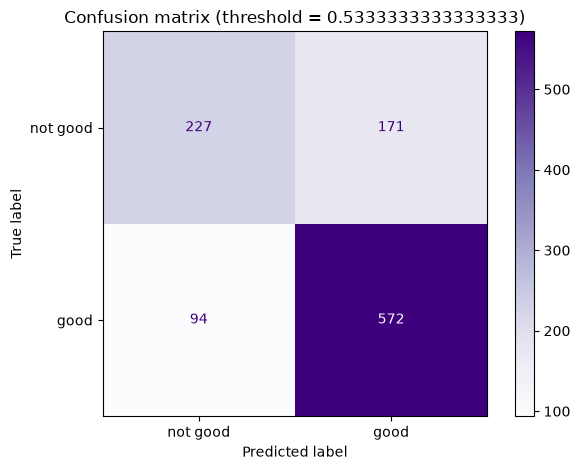

In [13]:
from wine_quality.evaluate import evaluate_test, plot_confusion_matrix

print(evaluate_test(best_pipeline, X_test, y_test, threshold))
plot_confusion_matrix(best_pipeline, X_test, y_test, threshold)

In [14]:
import pandas as pd
from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_pipeline, X_val, y_val, scoring="f1",
    n_repeats=10, random_state=loader.cfg["model"]["random_state"],
)
importance = pd.Series(result.importances_mean, index=X_val.columns)
importance.sort_values(ascending=False)

alcohol                 0.049113
volatile acidity        0.037262
total sulfur dioxide    0.030193
sulphates               0.028072
citric acid             0.023633
pH                      0.020584
fixed acidity           0.017039
residual sugar          0.015072
chlorides               0.014111
free sulfur dioxide     0.009948
density                 0.008150
wine_type               0.001119
dtype: float64

## Interpretation

**Most important features.** The model relies mostly on alcohol, volatile acidity and total sulfur dioxide. This shows what the model uses, not what causes quality.

**Two limits.**
1. The data only contains Portuguese Vinho Verde wines rated by human tasters, so the model may not work for other wines.
2. The model is only moderately good (F1 0.81): 171 wines that are not good were called good.

**Ethical risks.** The model rates wines, not people, but its decisions affect people. A small producer could have a wine rejected because of one score, and the taste of one tasting panel becomes the standard.